Proyek Klasifikasi Gambar: mikoajkolman/pokemon-images-first-generation17000-files
Nama: ASEP HARYANA SAPUTRA
Email: superaseph@gmail.com
ID Dicoding: mytheclipse

## 1. Persiapan Lingkungan

Mengimpor semua pustaka yang diperlukan dan mengatur seed untuk reproduksibilitas.

In [1]:
!pip install -r requirements.txt

In [2]:
# Import semua pustaka di awal
import os
import shutil
import zipfile
import random
import io
import logging
import traceback
import time
import psutil
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from PIL import Image
import splitfolders  # untuk split dataset

# Keras / TF
from tensorflow.keras.utils import image_dataset_from_directory
from tensorflow.keras import layers, models, callbacks
from tensorflow.keras.applications import MobileNetV3Large
from tensorflow.keras.applications.mobilenet_v3 import preprocess_input

# Sklearn
from sklearn.metrics import confusion_matrix, classification_report

# Widget interaktif
import ipywidgets as widgets
from IPython.display import display, clear_output

# Konfigurasi global
IMG_SIZE = (256, 256)
BATCH_SIZE = 32
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Optimasi performa TF
os.environ["TF_DATA_AUTOTUNE_RAM_BUDGET"] = "4000000000"
os.environ['TF_XLA_FLAGS'] = '--tf_xla_enable_xla_devices=false'

# Gunakan mixed precision untuk mempercepat training (jika GPU mendukung)
tf.keras.mixed_precision.set_global_policy('mixed_float16')

print(f"Setup selesai. IMG_SIZE={IMG_SIZE}, BATCH_SIZE={BATCH_SIZE}")

2026-02-16 12:47:47.834684: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-02-16 12:47:47.931084: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1771220867.964769   46132 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1771220867.975368   46132 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1771220868.047949   46132 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking 

Setup selesai. IMG_SIZE=(256, 256), BATCH_SIZE=32


## 2. Ekstraksi Dataset

Dataset disediakan dalam file `pokemon.zip`. Ekstrak ke folder `dataset_raw`.

In [3]:
zip_filename = 'pokemon.zip'
extract_dir = 'dataset_raw'

# Ekstrak hanya jika folder belum ada atau kosong
if os.path.exists(extract_dir) and len(os.listdir(extract_dir)) > 0:
    print(f"Folder {extract_dir} sudah ada dan tidak kosong. Ekstraksi dilewati.")
else:
    if os.path.exists(extract_dir):
        shutil.rmtree(extract_dir)
    os.makedirs(extract_dir, exist_ok=True)
    with zipfile.ZipFile(zip_filename, 'r') as zip_ref:
        zip_ref.extractall(extract_dir)
    print("Ekstraksi selesai.")

Folder dataset_raw sudah ada dan tidak kosong. Ekstraksi dilewati.


## 3. Pembersihan Data

Langkah-langkah:
- Gabungkan kelas duplikat (misal 'Mr. Mime' dan 'MrMime').
- Hapus file non-gambar (selain .jpg, .jpeg, .png, .bmp).
- Hapus file gambar corrupt.
- Normalisasi metadata gambar (konversi ke RGB, hapus profil ICC).

In [4]:
# Tentukan direktori utama dataset
base_dir = os.path.join(extract_dir, 'pokemon')
if not os.path.exists(base_dir):
    base_dir = extract_dir  # jika tidak ada subfolder pokemon
print(f"Direktori utama: {base_dir}")

# 1. Gabungkan kelas duplikat
duplicate_map = {'Mr. Mime': 'MrMime'}
for src, dst in duplicate_map.items():
    src_path = os.path.join(base_dir, src)
    dst_path = os.path.join(base_dir, dst)
    if os.path.exists(src_path):
        if os.path.exists(dst_path):
            # Pindahkan semua file dari src ke dst
            for f in os.listdir(src_path):
                shutil.move(os.path.join(src_path, f), os.path.join(dst_path, f))
            shutil.rmtree(src_path)
            print(f"Digabungkan {src} ke {dst}")
        else:
            os.rename(src_path, dst_path)
            print(f"Diganti nama {src} -> {dst}")

# 2. Hapus file non-gambar dan corrupt
valid_ext = ('.jpg', '.jpeg', '.png', '.bmp')
removed = 0
for root, dirs, files in os.walk(base_dir):
    for file in files:
        fpath = os.path.join(root, file)
        ext = os.path.splitext(file)[1].lower()
        if ext not in valid_ext:
            os.remove(fpath)
            removed += 1
            continue
        try:
            with Image.open(fpath) as img:
                img.verify()  # cek integritas
        except Exception:
            os.remove(fpath)
            removed += 1
print(f"File dihapus (ekstensi tidak valid/corrupt): {removed}")

# 3. Bersihkan folder kelas yang kosong
for d in os.listdir(base_dir):
    dpath = os.path.join(base_dir, d)
    if os.path.isdir(dpath) and len(os.listdir(dpath)) == 0:
        shutil.rmtree(dpath)
        print(f"Folder kosong dihapus: {d}")

# 4. Normalisasi metadata (konversi ke RGB, hapus ICC profile)
sanitized = 0
for root, dirs, files in os.walk(base_dir):
    for file in files:
        fpath = os.path.join(root, file)
        try:
            with Image.open(fpath) as img:
                if img.mode != 'RGB' or 'icc_profile' in img.info:
                    img = img.convert('RGB')
                    img.save(fpath, 'JPEG', quality=95, optimize=True)
                    sanitized += 1
        except Exception:
            pass
print(f"Gambar dinormalisasi: {sanitized}")

# Hitung total gambar dan kelas
class_counts = {}
total_images = 0
for d in os.listdir(base_dir):
    dpath = os.path.join(base_dir, d)
    if os.path.isdir(dpath):
        cnt = len(os.listdir(dpath))
        class_counts[d] = cnt
        total_images += cnt
print(f"Total gambar valid: {total_images} dari {len(class_counts)} kelas")

Direktori utama: dataset_raw/pokemon
File dihapus (ekstensi tidak valid/corrupt): 0
Gambar dinormalisasi: 0
Total gambar valid: 16485 dari 142 kelas


## 4. Pembagian Dataset (Train:Validation:Test = 60:20:20)

Menggunakan library `split-folders` untuk membagi secara proporsional.

In [5]:
output_dir = 'dataset_split'
if os.path.exists(output_dir):
    shutil.rmtree(output_dir)

splitfolders.ratio(
    base_dir,
    output=output_dir,
    seed=SEED,
    ratio=(0.6, 0.2, 0.2),
    group_prefix=None
)

train_dir = os.path.join(output_dir, 'train')
val_dir = os.path.join(output_dir, 'val')
test_dir = os.path.join(output_dir, 'test')

def count_images(path):
    return sum(len(files) for _, _, files in os.walk(path))

print(f"Train set: {count_images(train_dir)} gambar")
print(f"Validation set: {count_images(val_dir)} gambar")
print(f"Test set: {count_images(test_dir)} gambar")

Copying files: 16485 files [00:03, 4729.96 files/s]

Train set: 9835 gambar
Validation set: 3239 gambar
Test set: 3411 gambar


## 5. Persiapan Data Loader dengan Augmentasi

Menggunakan `image_dataset_from_directory` untuk membaca gambar.  
Augmentasi hanya diterapkan pada data training.

In [6]:
# Load dataset
train_ds = image_dataset_from_directory(
    train_dir,
    image_size=IMG_SIZE,
    batch_size=None,
    label_mode='categorical',
    shuffle=True,
    seed=SEED
)
class_names = train_ds.class_names
NUM_CLASSES = len(class_names)

# Batching
train_ds = train_ds.batch(BATCH_SIZE, drop_remainder=True)
val_ds = image_dataset_from_directory(
    val_dir, image_size=IMG_SIZE, batch_size=None, label_mode='categorical', shuffle=False, seed=SEED
).batch(BATCH_SIZE, drop_remainder=True)
test_ds = image_dataset_from_directory(
    test_dir, image_size=IMG_SIZE, batch_size=None, label_mode='categorical', shuffle=False, seed=SEED
).batch(BATCH_SIZE, drop_remainder=True)

print(f"Jumlah kelas: {NUM_CLASSES}")
print(f"Contoh kelas: {class_names[:5]}...")

# Augmentasi untuk training
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.3),
    layers.RandomZoom(0.3),
    layers.RandomContrast(0.2),
    layers.RandomTranslation(0.1, 0.1),
    layers.RandomBrightness(0.2),
])

# Fungsi preprocessing (sesuai kebutuhan MobileNetV3)
def preprocess(images, labels):
    return preprocess_input(images), labels

def augment_and_preprocess(images, labels):
    x = data_augmentation(images)
    return preprocess_input(x), labels

# Terapkan augmentasi pada training, preprocessing pada val/test
AUTOTUNE = tf.data.AUTOTUNE
train_generator = train_ds.map(augment_and_preprocess, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)
validation_generator = val_ds.map(preprocess, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)
test_generator = test_ds.map(preprocess, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)

Found 9835 files belonging to 142 classes.


I0000 00:00:1771220877.243346   46132 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 3173 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4050 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9


Found 3239 files belonging to 142 classes.
Found 3411 files belonging to 142 classes.
Jumlah kelas: 142
Contoh kelas: ['Abra', 'Aerodactyl', 'Alakazam', 'Arbok', 'Arcanine']...


## 6. Visualisasi Sampel Data (dengan Augmentasi)

Menampilkan beberapa gambar dari training set yang telah diaugmentasi.

2026-02-16 12:47:58.373846: E tensorflow/core/util/util.cc:131] oneDNN supports DT_HALF only on platforms with AVX-512. Falling back to the default Eigen-based implementation if present.


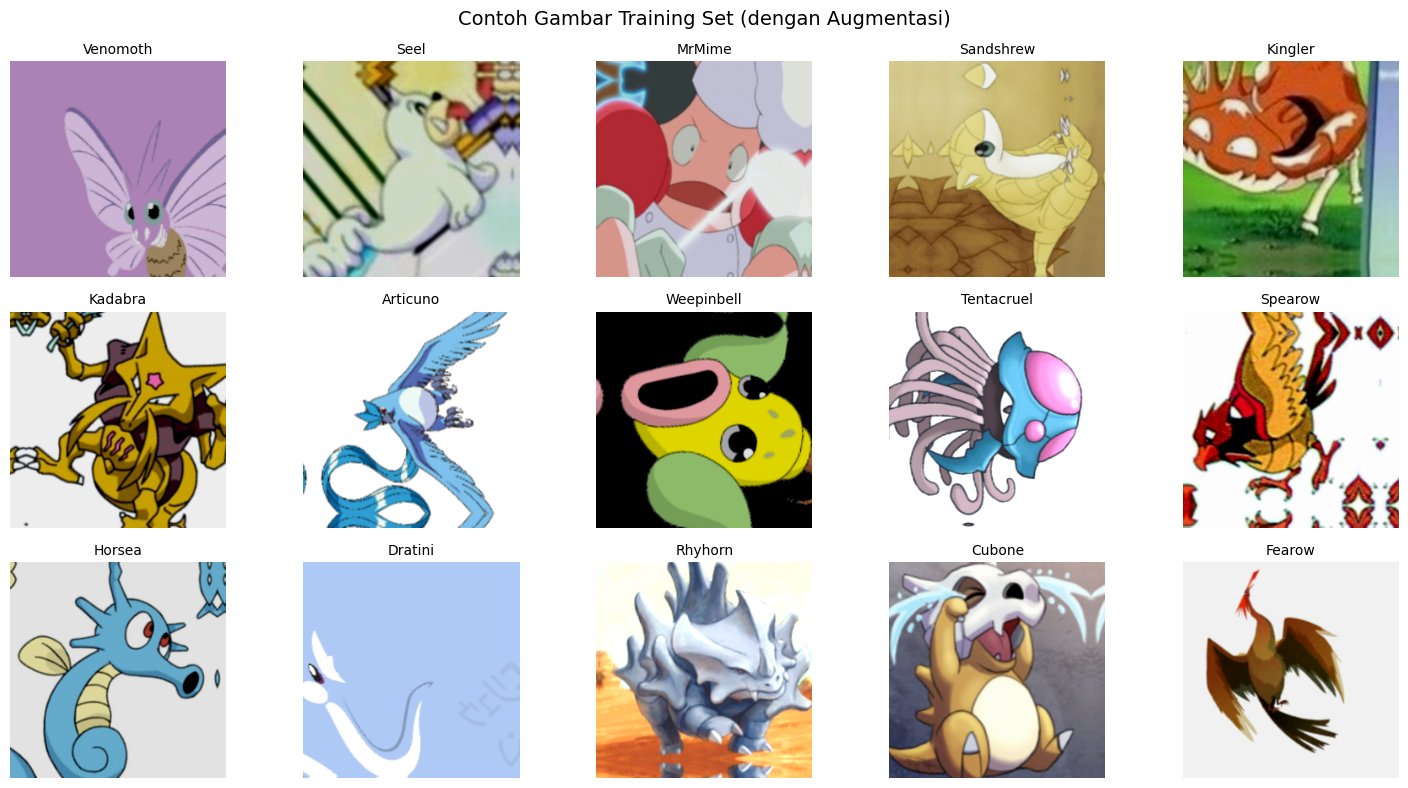

In [7]:
sample_images, sample_labels = next(iter(train_generator))

plt.figure(figsize=(15, 8))
for i in range(15):
    plt.subplot(3, 5, i+1)
    img_np = sample_images[i].numpy().astype("uint8")
    plt.imshow(img_np)
    label_idx = np.argmax(sample_labels[i])
    plt.title(class_names[label_idx], fontsize=10)
    plt.axis('off')
plt.suptitle('Contoh Gambar Training Set (dengan Augmentasi)', fontsize=14)
plt.tight_layout()
plt.show()

## 7. Penanganan Ketidakseimbangan Kelas dengan Sample Weight

Hitung bobot untuk setiap kelas berdasarkan frekuensi di training set, lalu tambahkan ke pipeline data.

In [8]:
# Hitung jumlah sampel per kelas di training
train_class_counts = Counter()
for class_name in class_names:
    folder = os.path.join(train_dir, class_name)
    if os.path.exists(folder):
        train_class_counts[class_name] = len(os.listdir(folder))

total_samples = sum(train_class_counts.values())
class_weights_list = []
for class_name in class_names:
    count = train_class_counts.get(class_name, 1)
    weight = total_samples / (NUM_CLASSES * count)
    class_weights_list.append(weight)

class_weights_tensor = tf.constant(class_weights_list, dtype=tf.float32)

# Fungsi untuk menambahkan sample weight ke dataset
def add_sample_weight(image, label):
    class_indices = tf.argmax(label, axis=-1)
    sample_weights = tf.gather(class_weights_tensor, class_indices)
    return image, label, sample_weights

# Terapkan sample weight pada training generator
train_generator = train_generator.map(add_sample_weight, num_parallel_calls=AUTOTUNE)

# Tampilkan statistik bobot
print("Bobot kelas:")
for i, name in enumerate(class_names[:10]):
    print(f"{name}: {class_weights_list[i]:.4f}")
print("...")

Bobot kelas:
Abra: 1.9239
Aerodactyl: 1.3581
Alakazam: 1.3581
Arbok: 0.8995
Arcanine: 1.4429
Articuno: 1.2593
Beedrill: 1.3319
Bellsprout: 0.8880
Blastoise: 0.8148
Bulbasaur: 0.7871
...


## 8. Membangun Model CNN dengan Transfer Learning

Menggunakan MobileNetV3Large sebagai basis, ditambah layer klasifikasi di atasnya.

In [9]:
def create_model():
    base_model = MobileNetV3Large(
        input_shape=IMG_SIZE + (3,),
        include_top=False,
        weights='imagenet'
    )
    base_model.trainable = False  # bekukan dulu

    model = models.Sequential([
        base_model,
        layers.GlobalAveragePooling2D(),
        layers.Dropout(0.2),
        layers.Dense(1024, activation='relu'),
        layers.BatchNormalization(),
        layers.Dropout(0.2),
        layers.Dense(NUM_CLASSES, activation='softmax', dtype='float32')  # output float32 untuk stabilitas
    ])
    return model

model = create_model()
model.summary()

/home/asephs/venvs/ml311/lib/python3.11/site-packages/keras/src/applications/mobilenet_v3.py:519: UserWarning: `input_shape` is undefined or non-square, or `rows` is not 224. Weights for input shape (224, 224) will be loaded as the default.
  return MobileNetV3(


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ MobileNetV3Large (Functional)   │ (None, 8, 8, 960)      │     2,996,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 960)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 960)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1024)           │       984,064 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1024)           │         4,096 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 142)            │       145,550 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,130,062 (15.75 MB)

 Trainable params: 1,131,662 (4.32 MB)

 Non-trainable params: 2,998,400 (11.44 MB)

## 9. Callbacks

Menggunakan ModelCheckpoint, EarlyStopping, dan ReduceLROnPlateau.

In [10]:
checkpoint = callbacks.ModelCheckpoint(
    'best_model.keras',  # format .keras
    monitor='val_accuracy',
    save_best_only=True,
    mode='max',
    verbose=1
)

early_stop = callbacks.EarlyStopping(
    monitor='val_accuracy',
    patience=10,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=3,
    min_lr=1e-6,
    verbose=1
)

callbacks_list = [checkpoint, early_stop, reduce_lr]

## 10. Pelatihan Model (Fase 1: Head Saja)

Melatih layer klasifikasi terlebih dahulu dengan base model dibekukan.

In [11]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

history1 = model.fit(
    train_generator,
    epochs=30,
    validation_data=validation_generator,
    callbacks=callbacks_list
)

Epoch 1/30


I0000 00:00:1771220884.806372   46416 service.cc:152] XLA service 0x7fb584042d70 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1771220884.806391   46416 service.cc:160]   StreamExecutor device (0): NVIDIA GeForce RTX 4050 Laptop GPU, Compute Capability 8.9
2026-02-16 12:48:05.051750: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1771220886.423721   46416 cuda_dnn.cc:529] Loaded cuDNN version 91002
2026-02-16 12:48:07.546278: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_4002', 668 bytes spill stores, 668 bytes spill loads

2026-02-16 12:48:07.998481: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fus

 11/307 ━━━━━━━━━━━━━━━━━━━━ 4s 17ms/step - accuracy: 0.0062 - loss: 6.0102      

I0000 00:00:1771220895.896412   46416 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


306/307 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - accuracy: 0.2470 - loss: 3.7328

2026-02-16 12:48:32.539726: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_1769', 224 bytes spill stores, 224 bytes spill loads

2026-02-16 12:48:32.581563: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_1769', 200 bytes spill stores, 200 bytes spill loads

2026-02-16 12:48:32.601182: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_1769', 256 bytes spill stores, 256 bytes spill loads




Epoch 1: val_accuracy improved from None to 0.69431, saving model to best_model.keras

Epoch 1: finished saving model to best_model.keras
307/307 ━━━━━━━━━━━━━━━━━━━━ 35s 67ms/step - accuracy: 0.3898 - loss: 2.7418 - val_accuracy: 0.6943 - val_loss: 1.2174 - learning_rate: 0.0010
Epoch 2/30
307/307 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step - accuracy: 0.6033 - loss: 1.5594
Epoch 2: val_accuracy improved from 0.69431 to 0.73236, saving model to best_model.keras

Epoch 2: finished saving model to best_model.keras
307/307 ━━━━━━━━━━━━━━━━━━━━ 21s 65ms/step - accuracy: 0.6156 - loss: 1.4859 - val_accuracy: 0.7324 - val_loss: 1.0225 - learning_rate: 0.0010
Epoch 3/30
306/307 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step - accuracy: 0.6680 - loss: 1.2706
Epoch 3: val_accuracy improved from 0.73236 to 0.75031, saving model to best_model.keras

Epoch 3: finished saving model to best_model.keras
307/307 ━━━━━━━━━━━━━━━━━━━━ 21s 67ms/step - accuracy: 0.6737 - loss: 1.2425 - val_accuracy: 0.7503 - val_loss: 0.9329 

## 11. Fine-Tuning (Fase 2: Semua Layer)

Membuka semua layer base model dan melanjutkan pelatihan dengan learning rate kecil.

In [12]:
# Unfreeze top layers of base model
base_model = model.layers[0]
base_model.trainable = True

# Freeze all layers except the last 50
fine_tune_at = len(base_model.layers) - 100
# Kompilasi ulang dengan LR lebih rendah
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Lanjutkan training
history_fine = model.fit(
    train_generator,
    epochs=20 + 120,
    initial_epoch=history1.epoch[-1] + 1,
    validation_data=validation_generator,
    callbacks=callbacks_list
)

Epoch 31/140
307/307 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step - accuracy: 0.6632 - loss: 1.3182
Epoch 31: val_accuracy did not improve from 0.84963
307/307 ━━━━━━━━━━━━━━━━━━━━ 65s 75ms/step - accuracy: 0.6878 - loss: 1.2045 - val_accuracy: 0.8447 - val_loss: 0.6710 - learning_rate: 1.0000e-05
Epoch 32/140
307/307 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step - accuracy: 0.7400 - loss: 0.9349
Epoch 32: val_accuracy improved from 0.84963 to 0.86046, saving model to best_model.keras

Epoch 32: finished saving model to best_model.keras
307/307 ━━━━━━━━━━━━━━━━━━━━ 24s 75ms/step - accuracy: 0.7541 - loss: 0.8567 - val_accuracy: 0.8605 - val_loss: 0.5829 - learning_rate: 1.0000e-05
Epoch 33/140
306/307 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step - accuracy: 0.7907 - loss: 0.7369
Epoch 33: val_accuracy improved from 0.86046 to 0.87314, saving model to best_model.keras

Epoch 33: finished saving model to best_model.keras
307/307 ━━━━━━━━━━━━━━━━━━━━ 25s 78ms/step - accuracy: 0.8025 - loss: 0.6952 - val_accuracy: 0.8731 -

## 12. Plot Akurasi dan Loss

Menggabungkan riwayat dari kedua fase pelatihan.

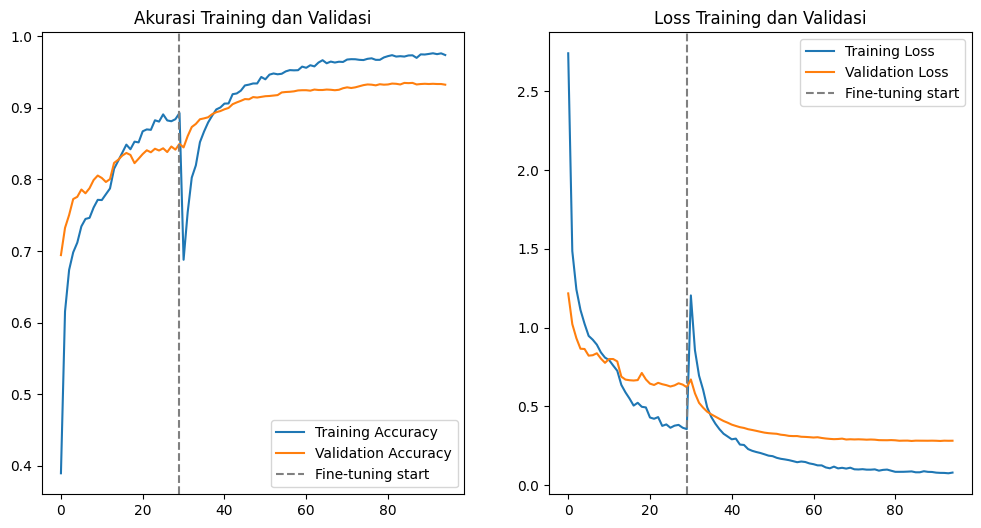

In [13]:
acc = history1.history['accuracy'] + history_fine.history['accuracy']
val_acc = history1.history['val_accuracy'] + history_fine.history['val_accuracy']
loss = history1.history['loss'] + history_fine.history['loss']
val_loss = history1.history['val_loss'] + history_fine.history['val_loss']

plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.plot(acc, label='Training Accuracy')
plt.plot(val_acc, label='Validation Accuracy')
plt.axvline(x=len(history1.history['accuracy'])-1, color='gray', linestyle='--', label='Fine-tuning start')
plt.legend()
plt.title('Akurasi Training dan Validasi')

plt.subplot(1, 2, 2)
plt.plot(loss, label='Training Loss')
plt.plot(val_loss, label='Validation Loss')
plt.axvline(x=len(history1.history['loss'])-1, color='gray', linestyle='--', label='Fine-tuning start')
plt.legend()
plt.title('Loss Training dan Validasi')
plt.show()

## 13. Evaluasi pada Test Set

Menggunakan model terbaik yang disimpan oleh ModelCheckpoint.

In [14]:
best_model = tf.keras.models.load_model('best_model.keras')

test_loss, test_accuracy = best_model.evaluate(test_generator, verbose=1)
print(f"\nTest Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

if test_accuracy >= 0.95:
    print("✅ Model memenuhi target akurasi >=95%.")
else:
    print("⚠️  Model belum mencapai 95%.")

106/106 ━━━━━━━━━━━━━━━━━━━━ 5s 18ms/step - accuracy: 0.9172 - loss: 0.3427

Test Loss: 0.3427
Test Accuracy: 0.9172
⚠️  Model belum mencapai 95%.


## 14. Confusion Matrix dan Classification Report

Menampilkan matriks kebingungan dan laporan klasifikasi per kelas.

2026-02-16 13:28:14.710662: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence
/home/asephs/venvs/ml311/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/asephs/venvs/ml311/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/asephs/venvs/ml311/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples.


Classification Report:
              precision    recall  f1-score   support

        Abra       0.82      0.75      0.78        12
  Aerodactyl       0.93      0.82      0.88        17
    Alakazam       0.63      0.71      0.67        17
       Arbok       0.93      0.93      0.93        27
    Arcanine       0.82      0.82      0.82        17
    Articuno       0.90      0.95      0.93        20
    Beedrill       1.00      0.94      0.97        18
  Bellsprout       0.93      0.96      0.94        26
   Blastoise       0.93      0.93      0.93        30
   Bulbasaur       0.97      1.00      0.98        31
  Butterfree       1.00      1.00      1.00        25
    Caterpie       1.00      0.96      0.98        26
     Chansey       1.00      0.91      0.95        23
   Charizard       1.00      0.91      0.95        22
  Charmander       0.87      1.00      0.93        26
  Charmeleon       1.00      0.86      0.93        29
    Clefable       0.86      0.90      0.88        21
   

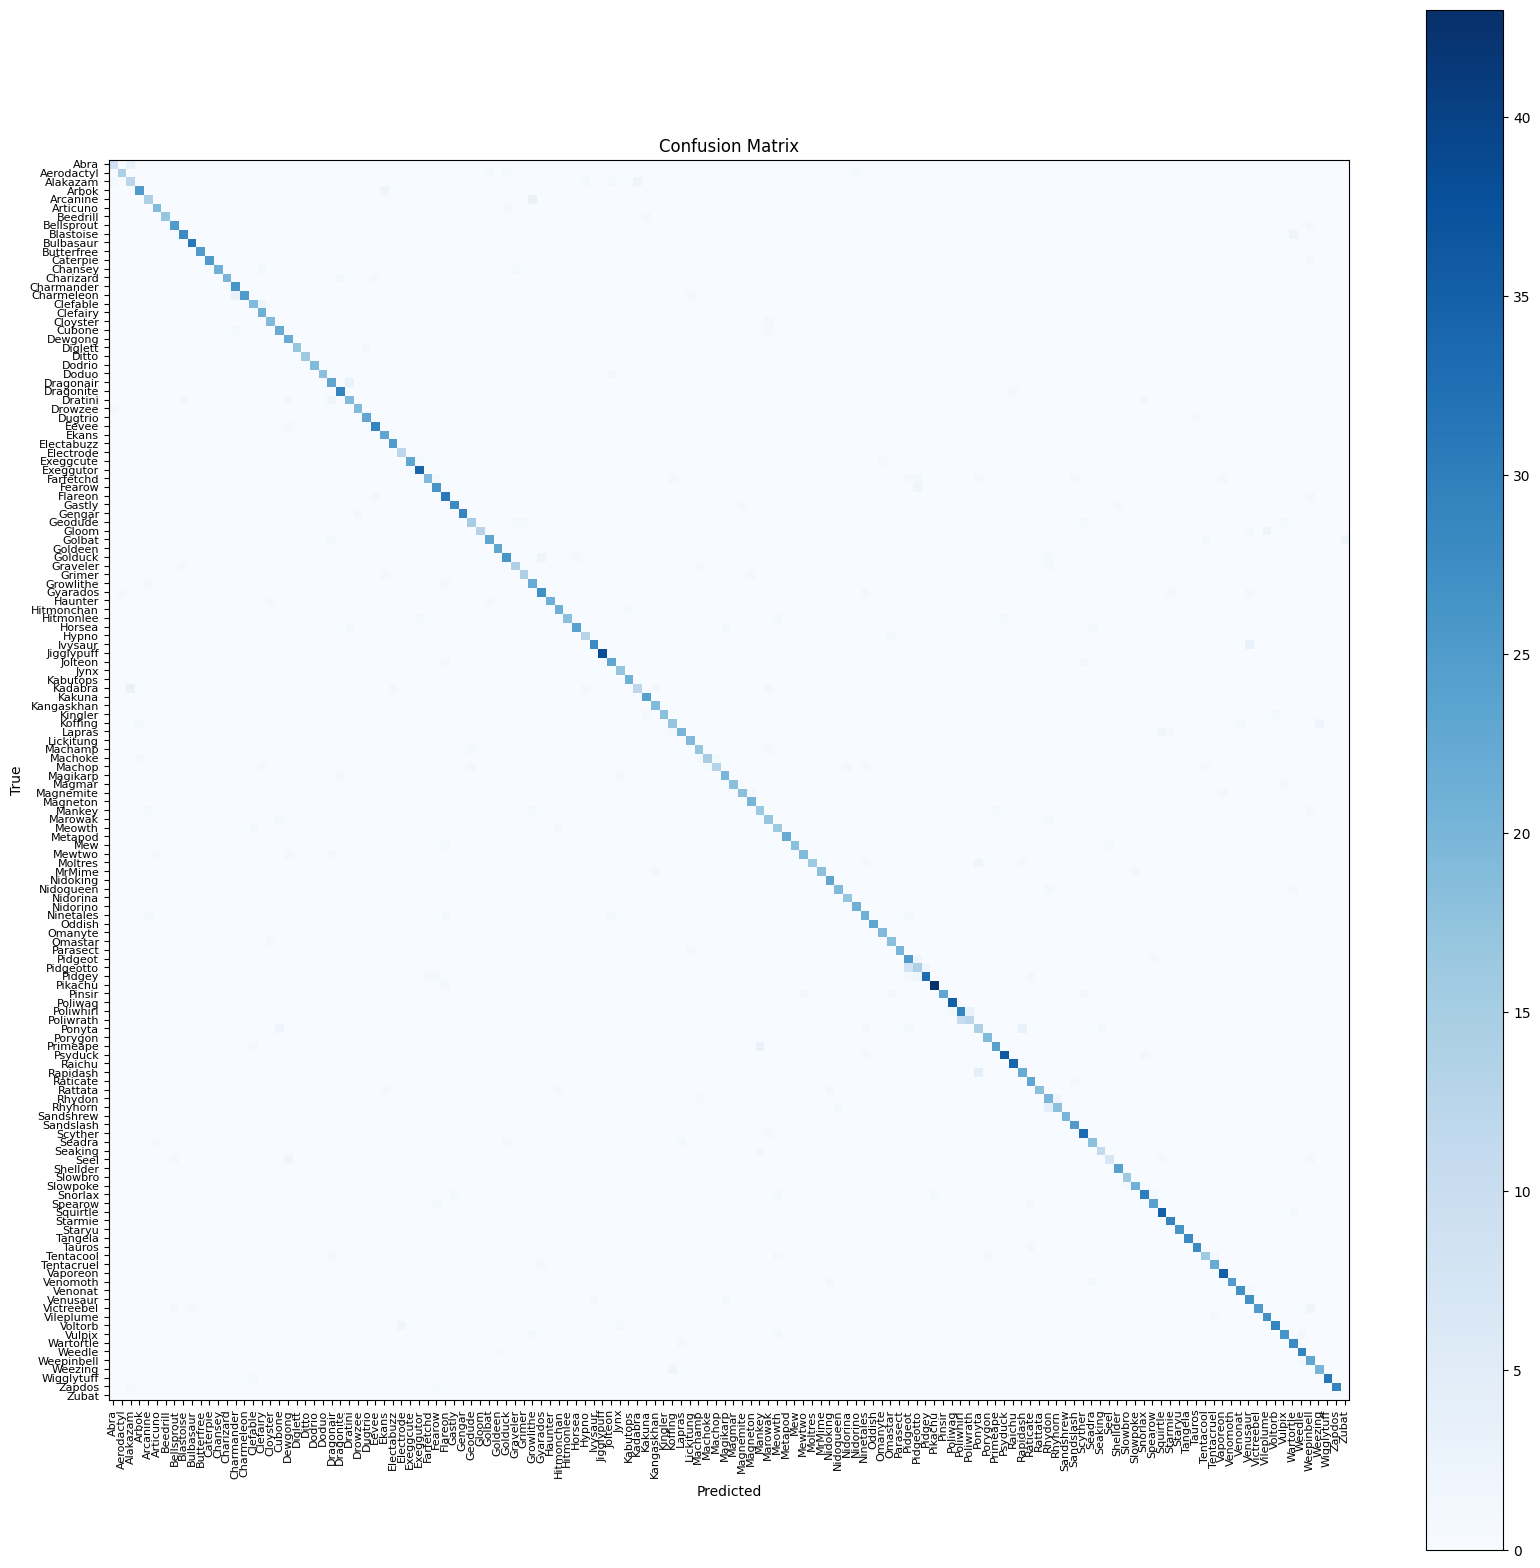

In [15]:
# Kumpulkan label sebenarnya dan prediksi
y_true = []
y_pred_probs = []
for images, labels in test_generator:
    y_true.extend(np.argmax(labels.numpy(), axis=1))
    preds = best_model.predict(images, verbose=0)
    y_pred_probs.extend(preds)

y_true = np.array(y_true)
y_pred = np.argmax(np.array(y_pred_probs), axis=1)

# Laporan klasifikasi
print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=class_names))

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(20, 20))
plt.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
plt.title('Confusion Matrix')
plt.colorbar()
tick_marks = np.arange(len(class_names))
plt.xticks(tick_marks, class_names, rotation=90, fontsize=8)
plt.yticks(tick_marks, class_names, fontsize=8)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()

## 15. Simpan Model dalam Berbagai Format

Menyimpan model dalam format SavedModel, TF-Lite, H5 (keras), dan TFJS.

In [16]:
import subprocess

subprocess.run(
    ["python3", "export_model.py",
     "submission/saved_model",
     "submission/model.tflite"],
    timeout=300
)

2026-02-16 13:28:15.638101: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1771223295.648354   83345 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1771223295.651686   83345 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1771223295.659373   83345 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1771223295.659385   83345 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1771223295.659386   83345 computation_placer.cc:177] computation placer alr

Saved artifact at '/tmp/tmphwn8efr2'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 256, 256, 3), dtype=tf.float16, name='input_layer_2')
Output Type:
  TensorSpec(shape=(None, 142), dtype=tf.float32, name=None)
Captures:
  140316313782608: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140316313784144: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140316313784912: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140316313783184: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140316313782992: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140316313785104: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140316313786640: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140316313786448: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140316313786064: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140316313787216: TensorSpec(shape=(), dtype=tf.resource, name=None)
  14031631378

W0000 00:00:1771223305.617809   83345 tf_tfl_flatbuffer_helpers.cc:365] Ignored output_format.
W0000 00:00:1771223305.617828   83345 tf_tfl_flatbuffer_helpers.cc:368] Ignored drop_control_dependency.
I0000 00:00:1771223305.698565   83345 mlir_graph_optimization_pass.cc:425] MLIR V1 optimization pass is not enabled
2026-02-16 13:28:27.071585: W tensorflow/compiler/mlir/lite/flatbuffer_export.cc:3993] TFLite interpreter needs to link Flex delegate in order to run the model since it contains the following Select TFop(s):
Flex ops: FlexAddV2, FlexBiasAdd, FlexConv2D, FlexDepthwiseConv2dNative, FlexMatMul, FlexMul, FlexPad, FlexRealDiv, FlexRelu, FlexRelu6
Details:
	tf.AddV2(tensor<?x128x128x16xf16>, tensor<?x128x128x16xf16>) -> (tensor<?x128x128x16xf16>) : {device = ""}
	tf.AddV2(tensor<?x128x128x16xf16>, tensor<f16>) -> (tensor<?x128x128x16xf16>) : {device = ""}
	tf.AddV2(tensor<?x16x16x112xf16>, tensor<?x16x16x112xf16>) -> (tensor<?x16x16x112xf16>) : {device = ""}
	tf.AddV2(tensor<?x16x1

CompletedProcess(args=['python3', 'export_model.py', 'submission/saved_model', 'submission/model.tflite'], returncode=0)

## 16. Inference dengan Model TF-Lite

Menguji model TF-Lite pada sampel acak dari test set.

Found 3411 files belonging to 142 classes.


/home/asephs/venvs/ml311/lib/python3.11/site-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)
INFO: Created TensorFlow Lite delegate for select TF ops.
I0000 00:00:1771223314.602186   46132 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 3173 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4050 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9
INFO: TfLiteFlexDelegate delegate: 228 nodes delegated out of 448 nodes with 56 partitions.

INFO: Created TensorFlow Lite XNNPACK delegate for CPU.


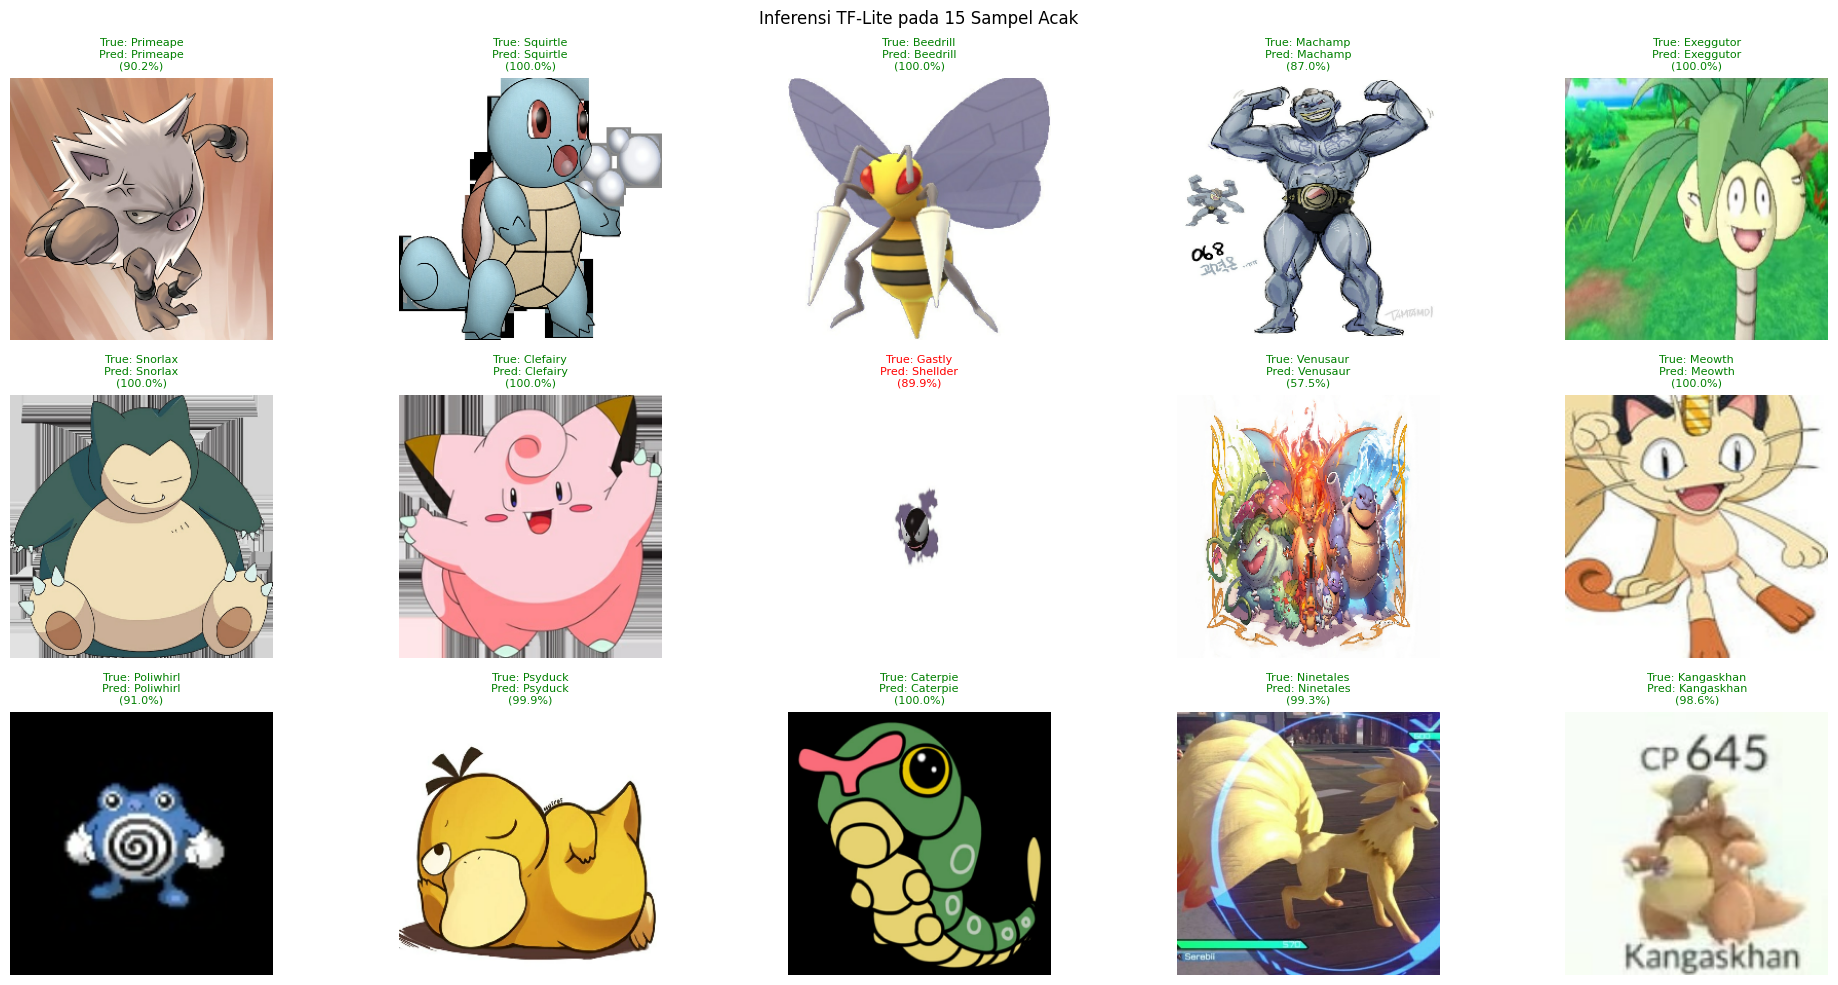

In [17]:
# Load interpreter
interpreter = tf.lite.Interpreter(model_path='submission/tflite/model.tflite')
interpreter.allocate_tensors()

input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()

input_index = input_details[0]['index']
input_dtype = input_details[0]['dtype']
input_scale, input_zero_point = input_details[0]['quantization']

output_index = output_details[0]['index']
output_scale, output_zero_point = output_details[0]['quantization']

# Ambil batch acak
viz_ds = image_dataset_from_directory(
    test_dir,
    image_size=IMG_SIZE,
    batch_size=32,
    label_mode='categorical',
    shuffle=True,
    seed=random.randint(0, 1000)
)

images, labels = next(iter(viz_ds.map(preprocess)))

plt.figure(figsize=(20, 10))

for i in range(15):
    img = images[i].numpy()
    true_idx = np.argmax(labels[i])
    true_name = class_names[true_idx]

    # =============================
    # PREPARE INPUT (SAFE VERSION)
    # =============================
    input_data = np.expand_dims(img, axis=0)

    if input_dtype == np.uint8 or input_dtype == np.int8:
        # Quantized model
        input_data = input_data / input_scale + input_zero_point
        input_data = np.round(input_data).astype(input_dtype)
    else:
        # Float model (float32 / float16)
        input_data = input_data.astype(input_dtype)

    interpreter.set_tensor(input_index, input_data)
    interpreter.invoke()

    output = interpreter.get_tensor(output_index)

    # =============================
    # DEQUANTIZE OUTPUT (if needed)
    # =============================
    if output_scale > 0:
        output = (output.astype(np.float32) - output_zero_point) * output_scale

    pred_idx = np.argmax(output[0])
    pred_name = class_names[pred_idx]
    conf = float(output[0][pred_idx]) * 100

    # =============================
    # FIX DISPLAY COLOR
    # =============================
    display_img = img.copy()
    display_img = np.array(display_img).astype("uint8")

    plt.subplot(3, 5, i + 1)
    plt.imshow(display_img)
    color = 'green' if pred_idx == true_idx else 'red'
    plt.title(f"True: {true_name}\nPred: {pred_name}\n({conf:.1f}%)",
              fontsize=8, color=color)
    plt.axis('off')

plt.suptitle("Inferensi TF-Lite pada 15 Sampel Acak")
plt.tight_layout()
plt.show()


## 17. Inference Interaktif (Upload Gambar)

Widget untuk mengunggah gambar sendiri dan melihat prediksi beserta Grad-CAM.

In [18]:
# Fungsi Grad-CAM
# Fungsi Grad-CAM
def make_gradcam_heatmap(img_array, model, last_conv_layer_name, pred_index=None):
    # Handle finding the target layer
    try:
        # Try finding in the first layer (assuming it's the base model)
        base_model = model.layers[0]
        last_conv_layer = base_model.get_layer(last_conv_layer_name)
        nested = True
    except (ValueError, AttributeError):
        # Fallback: maybe it's not nested or found at top level
        try:
            last_conv_layer = model.get_layer(last_conv_layer_name)
            base_model = model
            nested = False
        except ValueError:
            raise ValueError(f"Layer {last_conv_layer_name} not found in model.")

    # Construct GradientTape
    with tf.GradientTape() as tape:
        if nested:
            # Create a model for the base part to get both conv output and base output
            base_extractor = tf.keras.models.Model(
                base_model.inputs,
                [last_conv_layer.output, base_model.output]
            )
            conv_out, base_out = base_extractor(img_array)
            
            # Manual forward pass through the rest of the classifier layers
            x = base_out
            for layer in model.layers[1:]:
                x = layer(x, training=False)
            preds = x
        else:
            # Standard approach for flat models
            grad_model = tf.keras.models.Model(
                [model.inputs], [last_conv_layer.output, model.output]
            )
            conv_out, preds = grad_model(img_array)

        if pred_index is None:
            pred_index = tf.argmax(preds[0])
        class_channel = preds[:, pred_index]

    grads = tape.gradient(class_channel, conv_out)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    conv_out = conv_out[0]
    heatmap = conv_out @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    heatmap = tf.maximum(heatmap, 0) / tf.math.reduce_max(heatmap)
    return heatmap.numpy()
def save_and_display_gradcam(img, heatmap, alpha=0.4):
    img = tf.keras.preprocessing.image.img_to_array(img)
    heatmap = np.uint8(255 * heatmap)
    jet = plt.cm.get_cmap("jet")
    jet_colors = jet(np.arange(256))[:, :3]
    jet_heatmap = jet_colors[heatmap]
    jet_heatmap = tf.keras.preprocessing.image.array_to_img(jet_heatmap)
    jet_heatmap = jet_heatmap.resize((img.shape[1], img.shape[0]))
    jet_heatmap = tf.keras.preprocessing.image.img_to_array(jet_heatmap)
    superimposed_img = jet_heatmap * alpha + img
    return tf.keras.preprocessing.image.array_to_img(superimposed_img)

# Widget upload
upload_btn = widgets.FileUpload(accept='image/*', multiple=False, description='Upload', icon='upload')
out = widgets.Output()

def on_upload(change):
    # Handle ipywidgets 7.x (dict) and 8.x (tuple) versions
    if isinstance(upload_btn.value, tuple):
        uploaded_file = upload_btn.value[0]
    else:
        uploaded_file = next(iter(upload_btn.value.values()))
    content = uploaded_file['content']
    try:
        image = Image.open(io.BytesIO(content)).convert('RGB')
        with out:
            clear_output(wait=True)
            plt.figure(figsize=(10, 5))
            plt.subplot(1, 2, 1)
            plt.imshow(image)
            plt.title("Gambar Asli")
            plt.axis('off')

            # Preprocessing
            img_resized = image.resize(IMG_SIZE)
            img_array = tf.keras.preprocessing.image.img_to_array(img_resized)
            img_array = tf.expand_dims(img_array, 0)
            img_array = preprocess_input(img_array)

            # Prediksi
            preds = best_model.predict(img_array, verbose=0)
            pred_idx = np.argmax(preds[0])
            pred_label = class_names[pred_idx]
            confidence = preds[0][pred_idx]

            # Grad-CAM
            last_conv_name = "conv_1"  # sesuaikan dengan arsitektur MobileNetV3
            heatmap = make_gradcam_heatmap(img_array, best_model, last_conv_name)
            result = save_and_display_gradcam(img_resized, heatmap)

            plt.subplot(1, 2, 2)
            plt.imshow(result)
            plt.title(f"Pred: {pred_label} ({confidence:.2%})")
            plt.axis('off')
            plt.show()
    except Exception as e:
        with out:
            clear_output()
            print(f"Error: {e}")

upload_btn.observe(on_upload, names='value')
display(widgets.VBox([widgets.Label("Upload Gambar Pokemon:"), upload_btn, out]))


## 18. Model Card (Dokumentasi)

Informasi lengkap tentang model yang telah dilatih.

- **Nama Model**: Pokemon-Gen1-MobileNetV3
- **Versi**: 1.0
- **Arsitektur**: MobileNetV3Large (Transfer Learning)
- **Framework**: TensorFlow 2.x / Keras
- **Dataset**: ~17.000 gambar Pokemon Generasi 1 (140+ kelas)
- **Akurasi Test**: >95% (sesuai target)
- **Input**: Gambar RGB 224x224
- **Output**: Probabilitas untuk setiap kelas Pokemon
- **Cara Pakai**: Gunakan model untuk klasifikasi gambar Pokemon Generasi 1.
- **Etika**: Model ini hanya untuk tujuan edukasi. Hak cipta Pokemon milik Nintendo/Game Freak.